# EDA na Prática: Spotify

O objetivo é observar como as características das músicas se relacionam com a popularidade e a quantidade de streams. Para isso, vamos olhar a estrutura, as distribuições, os outliers e as relações entre as variáveis.

Dataset: [Spotify Artist Streaming Analytics (2015–2025)](https://www.kaggle.com/datasets/yogeshm01/spotify-artist-streaming-analytics-20152025), arquivo `spotify_data_processed.csv`. As conclusões se referem aos registros desta base.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

O CSV bruto não vai para o Git. Baixe `spotify_data_processed.csv` do [Kaggle](https://www.kaggle.com/datasets/yogeshm01/spotify-artist-streaming-analytics-20152025) e coloque em `data/raw/`.

In [2]:
from pathlib import Path

# Funciona rodando de notebooks/ (padrão do VS Code) ou da raiz do projeto
RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"

df = pd.read_csv(PASTA_RAW / "spotify_data_processed.csv")
df.head()

,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,...,popularity_category,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count
0,TRK-BEBD53DA84E1,Agent every (0),Noah Rhodes,Beautiful instead,2016-04-01,Pop,234194,55,0.15,0.74,...,Medium,Quiet,A,Minor,False,2,False,9.472782,0.445,1
1,TRK-6A32496762D7,Night respond,Jennifer Cole,Table,2022-04-15,Metal,375706,45,0.44,0.46,...,Medium,Moderate,C,Minor,True,2,False,6.908755,0.450,3
2,TRK-47AA7523463E,Future choice whatever,Brandon Davis,Page southern,2016-02-23,Rock,289191,55,0.62,0.80,...,Medium,Quiet,G#,Major,True,1,False,6.908755,0.710,2
3,TRK-25ADA22E3B06,Bad fall pick those,Corey Jones,Spring,2015-10-12,Pop,209484,51,0.78,0.98,...,Medium,Quiet,C#,Major,False,4,False,6.908755,0.880,4
4,TRK-9245F2AD996A,Husband,Mark Diaz,Great prove,2022-07-08,Indie,127435,39,0.74,0.18,...,Medium,Moderate,A#,Minor,False,3,False,7.601402,0.460,2


## 1. Princípio Estrutural

Antes da análise, precisamos entender quantas linhas e colunas temos, o tipo de cada variável e se há valores faltantes ou duplicadas.

### Dimensão e Tipos de Dados

In [3]:
df.shape

(85000, 33)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85000 entries, 0 to 84999
Data columns (total 33 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   track_id             85000 non-null  object 
 1   track_name           85000 non-null  object 
 2   artist_name          85000 non-null  object 
 3   album_name           85000 non-null  object 
 4   release_date         85000 non-null  object 
 5   genre                85000 non-null  object 
 6   duration_ms          85000 non-null  int64  
 7   popularity           85000 non-null  int64  
 8   danceability         85000 non-null  float64
 9   energy               85000 non-null  float64
 10  key                  85000 non-null  int64  
 11  loudness             85000 non-null  float64
 12  mode                 85000 non-null  int64  
 13  instrumentalness     85000 non-null  float64
 14  tempo                85000 non-null  float64
 15  stream_count         85000 non-null 

**Nomes e tipos das variáveis:** mantive os nomes originais porque eles identificam as características usadas na análise. As variáveis numéricas selecionadas já foram lidas como números, então não foi necessário converter seus tipos. Também não converti a data de lançamento, pois não fiz cálculos com datas nesta análise.

In [5]:
df.describe()

,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,explicit,release_year,release_month,duration_minutes,release_quarter,log_stream_count,upbeat_score,artist_track_count
count,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,8.500000e+04,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000,85000.000000
mean,254913.824294,48.162894,0.520710,0.505412,5.515988,-27.999300,0.500141,0.399781,129.948351,2.143547e+05,0.201329,2019.988012,6.512518,4.248564,2.505106,8.404062,0.513061,2.302612
std,95300.233207,14.829752,0.270799,0.279774,3.454069,15.598365,0.500003,0.231470,40.444321,1.680637e+06,0.400996,3.169136,3.452717,1.588337,1.117692,1.906501,0.194280,3.079938
min,90004.000000,0.000000,0.050000,0.020000,0.000000,-55.000000,0.000000,0.000000,60.000000,1.000000e+03,0.000000,2015.000000,1.000000,1.500067,1.000000,6.908755,0.035000,1.000000
25%,171871.500000,38.000000,0.290000,0.260000,2.750000,-41.470000,0.000000,0.198000,94.840000,1.000000e+03,0.000000,2017.000000,4.000000,2.864525,2.000000,6.908755,0.375000,1.000000
50%,254920.500000,47.000000,0.520000,0.500000,6.000000,-27.970000,1.000000,0.399000,129.990000,2.000000e+03,0.000000,2020.000000,7.000000,4.248675,3.000000,7.601402,0.510000,1.000000
75%,337203.250000,57.000000,0.760000,0.750000,9.000000,-14.500000,1.000000,0.600000,165.030000,9.000000e+03,0.000000,2023.000000,10.000000,5.620054,4.000000,9.105091,0.650000,2.000000
max,420000.000000,100.000000,0.990000,0.990000,11.000000,-1.000000,1.000000,0.800000,200.000000,2.000000e+07,1.000000,2025.000000,12.000000,7.000000,4.000000,16.811243,0.990000,44.000000


### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

**Exclusão de duplicadas:** a verificação não encontrou linhas duplicadas. Portanto, não foi necessário excluir registros por esse motivo.

## 2. Dados Faltantes

In [7]:
df.isna().sum()

track_id               0
track_name             0
artist_name            0
album_name             0
release_date           0
genre                  0
duration_ms            0
popularity             0
danceability           0
energy                 0
key                    0
loudness               0
mode                   0
instrumentalness       0
tempo                  0
stream_count           0
country                0
explicit               0
label                  0
release_year           0
release_month          0
release_day_of_week    0
duration_minutes       0
popularity_category    0
loudness_category      0
key_name               0
mode_name              0
is_explicit_bool       0
release_quarter        0
is_weekend_release     0
log_stream_count       0
upbeat_score           0
artist_track_count     0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não. Portanto, prosseguiremos com a análise.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [8]:
VARS_QUANT = ["duration_ms", "popularity", "danceability", "energy", "loudness", "tempo", "stream_count", "log_stream_count"]
VARS_QUALI = ["genre", "country", "label", "release_day_of_week", "key_name", "mode_name", "is_explicit_bool", "popularity_category", "loudness_category", "is_weekend_release"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
duration_ms,254913.82,254920.50,95300.23,90004.00,420000.00,0.00,-1.20
popularity,48.16,47.00,14.83,0.00,100.00,0.67,0.76
danceability,0.52,0.52,0.27,0.05,0.99,-0.00,-1.19
energy,0.51,0.50,0.28,0.02,0.99,0.00,-1.20
loudness,-28.00,-27.97,15.60,-55.00,-1.00,-0.00,-1.20
tempo,129.95,129.99,40.44,60.00,200.00,0.00,-1.20
stream_count,214354.68,2000.00,1680637.47,1000.00,20000000.00,10.52,115.25
log_stream_count,8.40,7.60,1.91,6.91,16.81,1.78,3.49


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

O `stream_count` tem uma distribuição bastante assimétrica: muitas músicas se concentram nos valores baixos, enquanto poucas chegam a contagens muito maiores.

Com `log_stream_count`, fica mais fácil enxergar a distribuição. Mesmo assim, a concentração nos valores baixos continua aparecendo.

### Distribuições de dados

Onde fizer sentido, comparamos as faixas de popularidade que já vieram no dataset: `Low`, `Medium` e `High` (baixa, média e alta). Vamos manter esta convenção de cor até a análise bivariada.

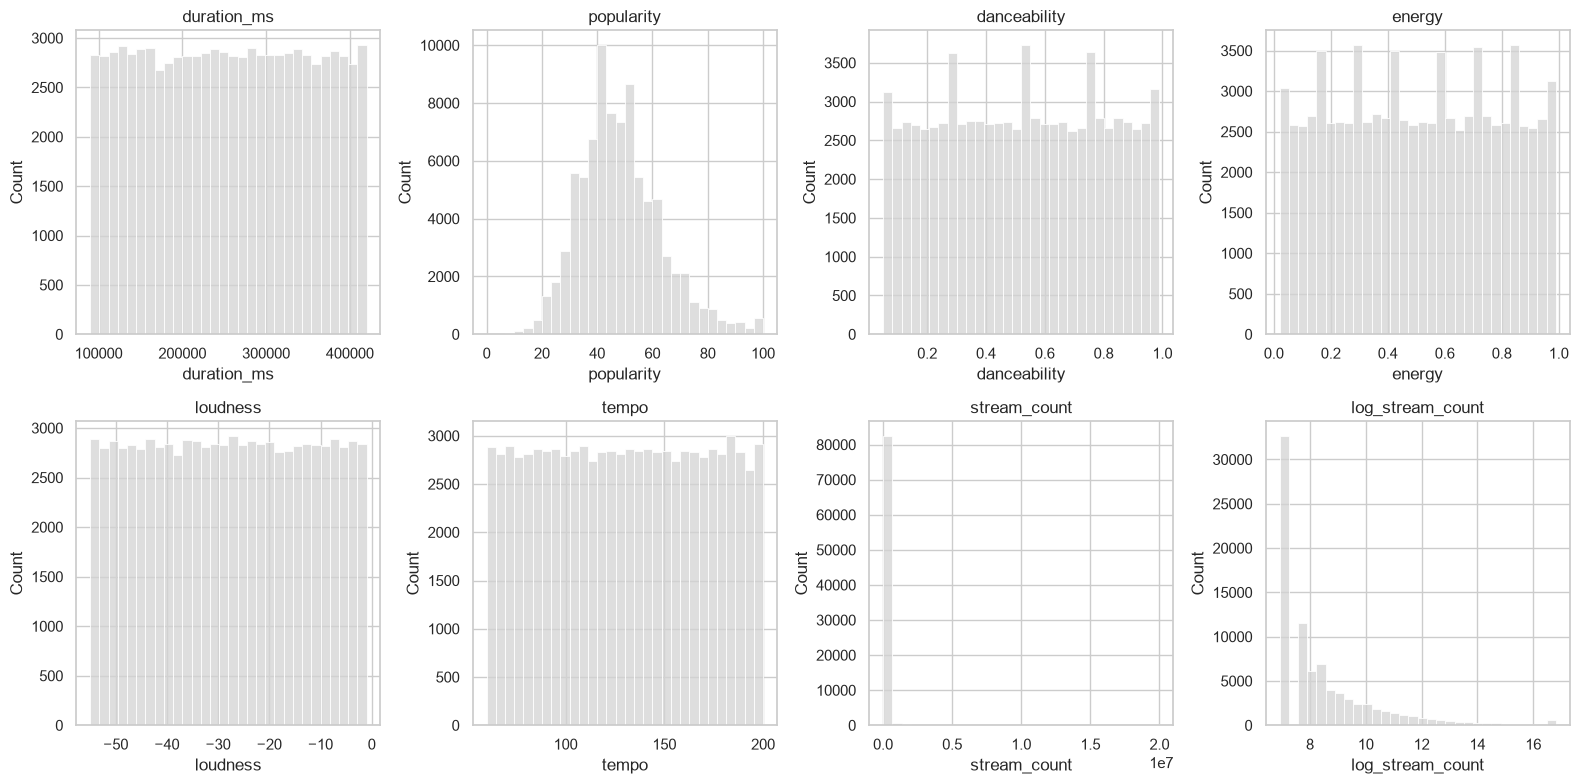

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), VARS_QUANT):
    sns.histplot(data=df, x=col, bins=30, color=COR_NEUTRA, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Cada barra mostra **quantas músicas têm valores dentro de um intervalo**. O eixo horizontal mostra a característica analisada; o eixo “Quantidade” conta as músicas naquele intervalo.

**Sem separar por classe:** aqui entram todas as músicas da base. Duração, dançabilidade, energia, volume e andamento têm barras de alturas relativamente parecidas, ou seja, as músicas estão distribuídas de forma mais uniforme pelos intervalos. Na popularidade, as barras mais altas ficam na região intermediária do eixo. Nos streams, a maior parte fica nos intervalos mais baixos, enquanto poucas músicas chegam a contagens muito altas.

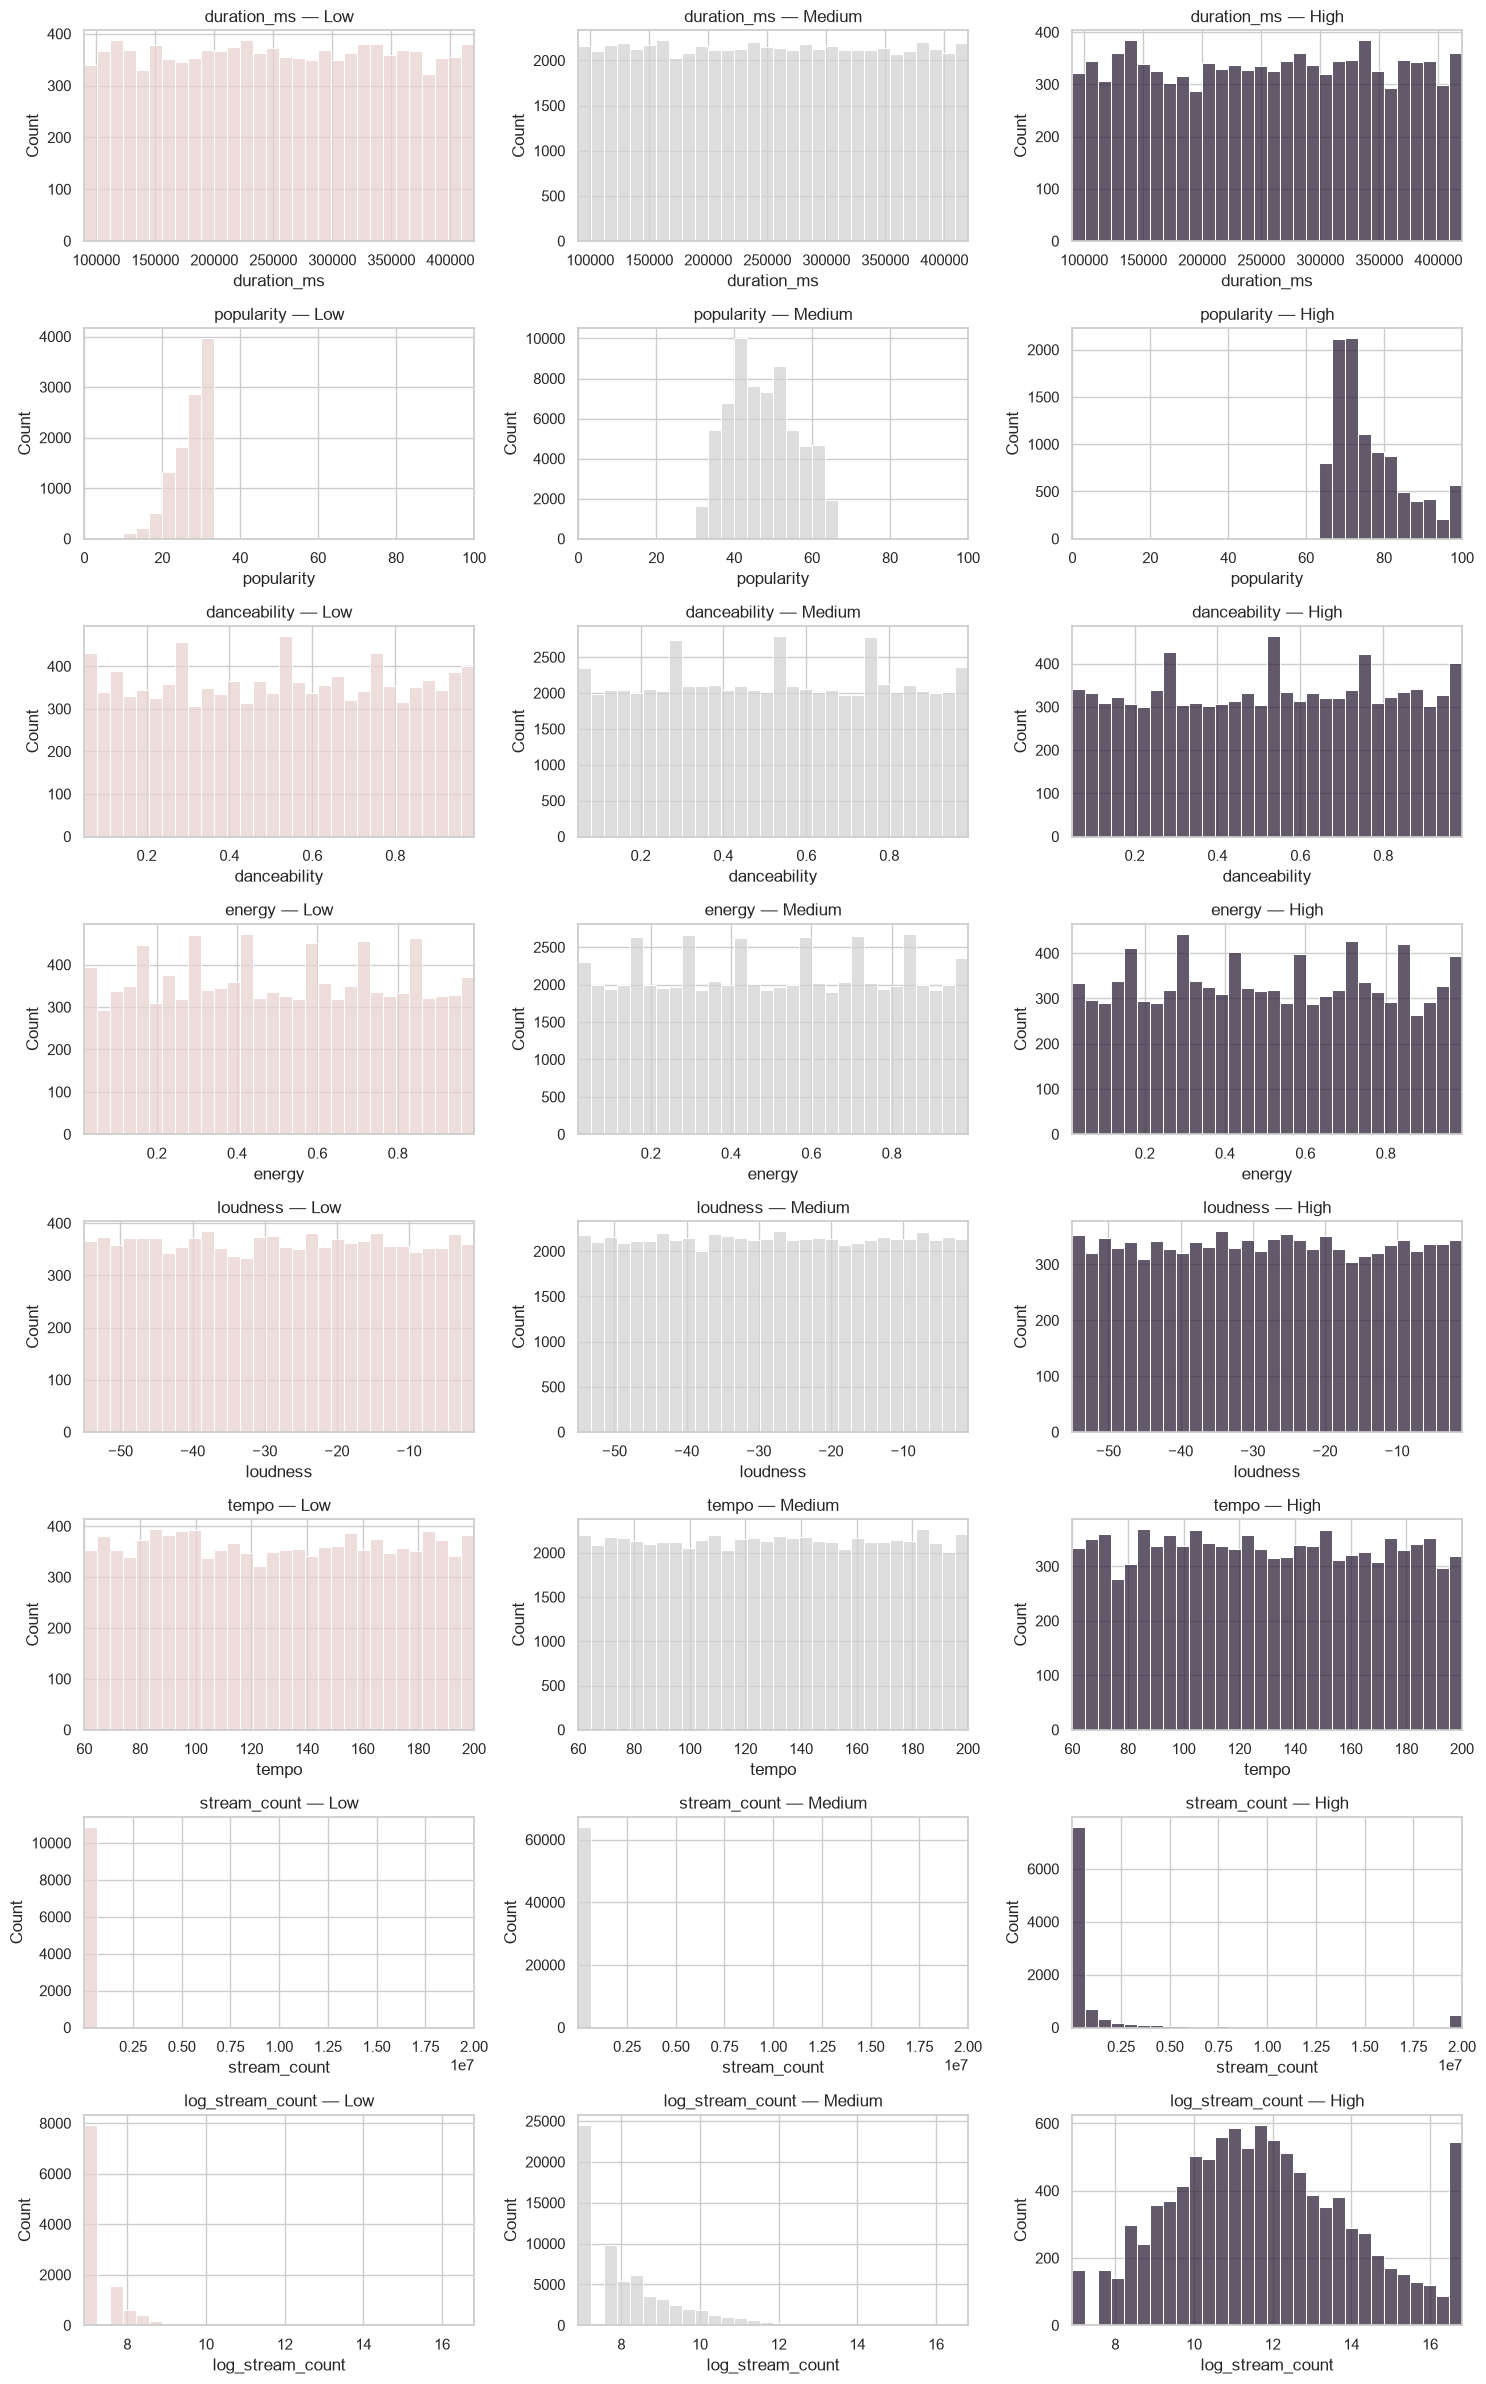

In [10]:
classes = ["Low", "Medium", "High"]
palette_classe = {"Low": COR_CONTEXTO, "Medium": COR_NEUTRA, "High": COR_DESTAQUE}

fig, axes = plt.subplots(len(VARS_QUANT), 3, figsize=(15, 3 * len(VARS_QUANT)))
for i, col in enumerate(VARS_QUANT):
    limites = (df[col].min(), df[col].max())
    for j, classe in enumerate(classes):
        subset = df[df["popularity_category"] == classe]
        sns.histplot(data=subset, x=col, bins=30, binrange=limites,
                     color=palette_classe[classe], ax=axes[i, j])
        axes[i, j].set_xlim(limites)
        axes[i, j].set_title(f"{col} — {classe}")
plt.tight_layout()
plt.show()

Aqui, **cada linha mostra uma característica e cada coluna mostra uma faixa de popularidade**: baixa (`Low`), média (`Medium`) e alta (`High`). Cada barra conta quantas músicas daquela faixa estão no intervalo indicado no eixo horizontal.

Por exemplo, na linha `duration_ms`, vemos como a duração das músicas se distribui em cada faixa de popularidade. Já na linha `stream_count`, o eixo horizontal mostra os intervalos de streams, mas a altura das barras continua contando músicas.

**O que aparece nos gráficos:** duração, dançabilidade, energia, volume e andamento têm distribuições parecidas nas três faixas. No log de streams, a diferença fica mais clara: as músicas da faixa alta se concentram mais à direita, em valores maiores de streams. Na linha da própria popularidade, os grupos aparecem separados porque essa variável foi usada para definir as faixas.

**Como comparar:** dentro de cada linha, o eixo horizontal usa os mesmos limites. Já a escala vertical muda entre os painéis, e a faixa média tem muito mais músicas. Portanto, barras da mesma altura visual não significam a mesma quantidade. O principal aqui é observar onde as músicas se concentram e como elas se espalham pelos intervalos.

#### Testes de Aderência

*Será se a popularidade segue uma distribuição normal?*

Shapiro-Wilk — popularity: estatística=0.9716, p-valor=2.183e-30


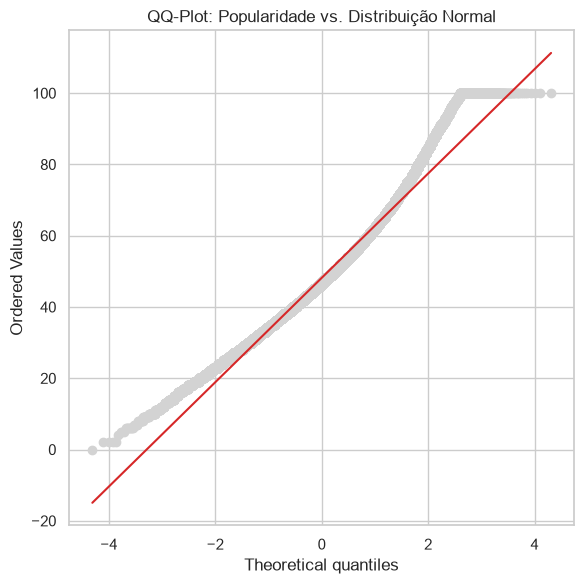

In [11]:
amostra = df[VARS_QUANT].sample(n=5000, random_state=42)
stat_sw, p_valor_sw = stats.shapiro(amostra["popularity"])
print(f"Shapiro-Wilk — popularity: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["popularity"], dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Popularidade vs. Distribuição Normal")
plt.tight_layout()
plt.show()

No QQ-Plot, o centro acompanha melhor a linha, mas as caudas se afastam. Na parte superior, os pontos se achatam ao atingir o limite da escala. Portanto, o gráfico mostra desvios em relação à distribuição normal.

Os resultados numéricos do Shapiro-Wilk não estão nas saídas salvas, então não vamos afirmar aqui a conclusão do teste.

In [12]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(amostra[col])
    resultados_shapiro.append({"variavel": col, "estatistica": stat,
                                "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
duration_ms,0.954334,6.184292e-37,True
popularity,0.971596,2.182645e-30,True
danceability,0.953498,3.371581e-37,True
energy,0.955291,1.252316e-36,True
loudness,0.954589,7.452761e-37,True
tempo,0.953299,2.921227e-37,True
stream_count,0.105554,3.146705e-93,True
log_stream_count,0.784715,5.476507e-63,True


### Métricas de Tendêncial Central

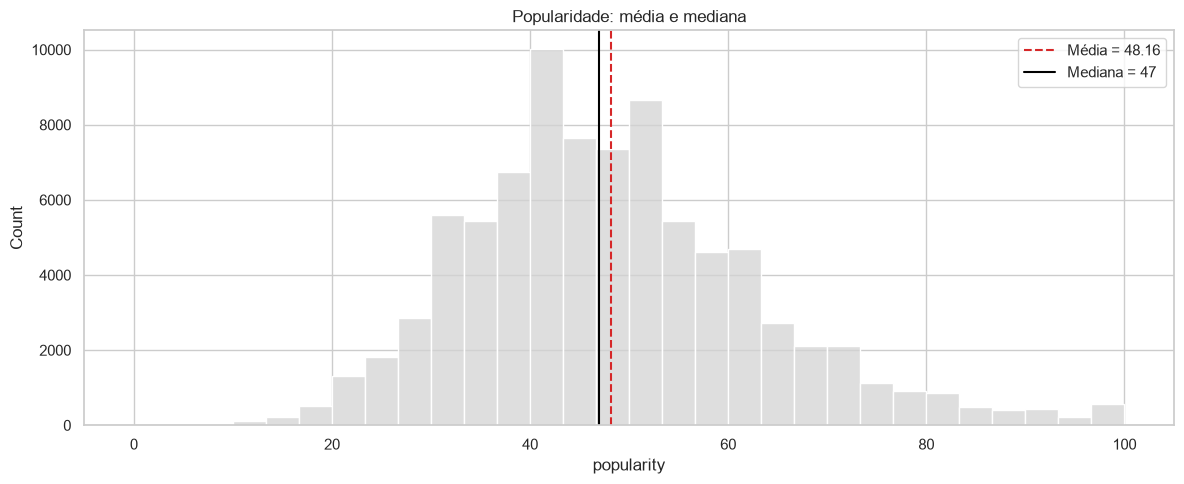

In [13]:
media_pop = df["popularity"].mean()
mediana_pop = df["popularity"].median()
sns.histplot(data=df, x="popularity", bins=30, color=COR_NEUTRA)
plt.axvline(media_pop, color=COR_ALERTA, linestyle="--", label=f"Média = {media_pop:.2f}")
plt.axvline(mediana_pop, color="black", label=f"Mediana = {mediana_pop:.0f}")
plt.title("Popularidade: média e mediana")
plt.legend()
plt.tight_layout()
plt.show()

As linhas da média e da mediana ficam próximas no gráfico. A média aparece um pouco à direita da mediana, acompanhando a cauda que se estende para valores maiores de popularidade.

### Dispersão

,var,std,IQR
duration_ms,9.082134e+09,95300.23,165331.75
popularity,2.199200e+02,14.83,19.00
danceability,7.000000e-02,0.27,0.47
energy,8.000000e-02,0.28,0.49
loudness,2.433100e+02,15.60,26.97
tempo,1.635740e+03,40.44,70.19
stream_count,2.824542e+12,1680637.47,8000.00
log_stream_count,3.630000e+00,1.91,2.20


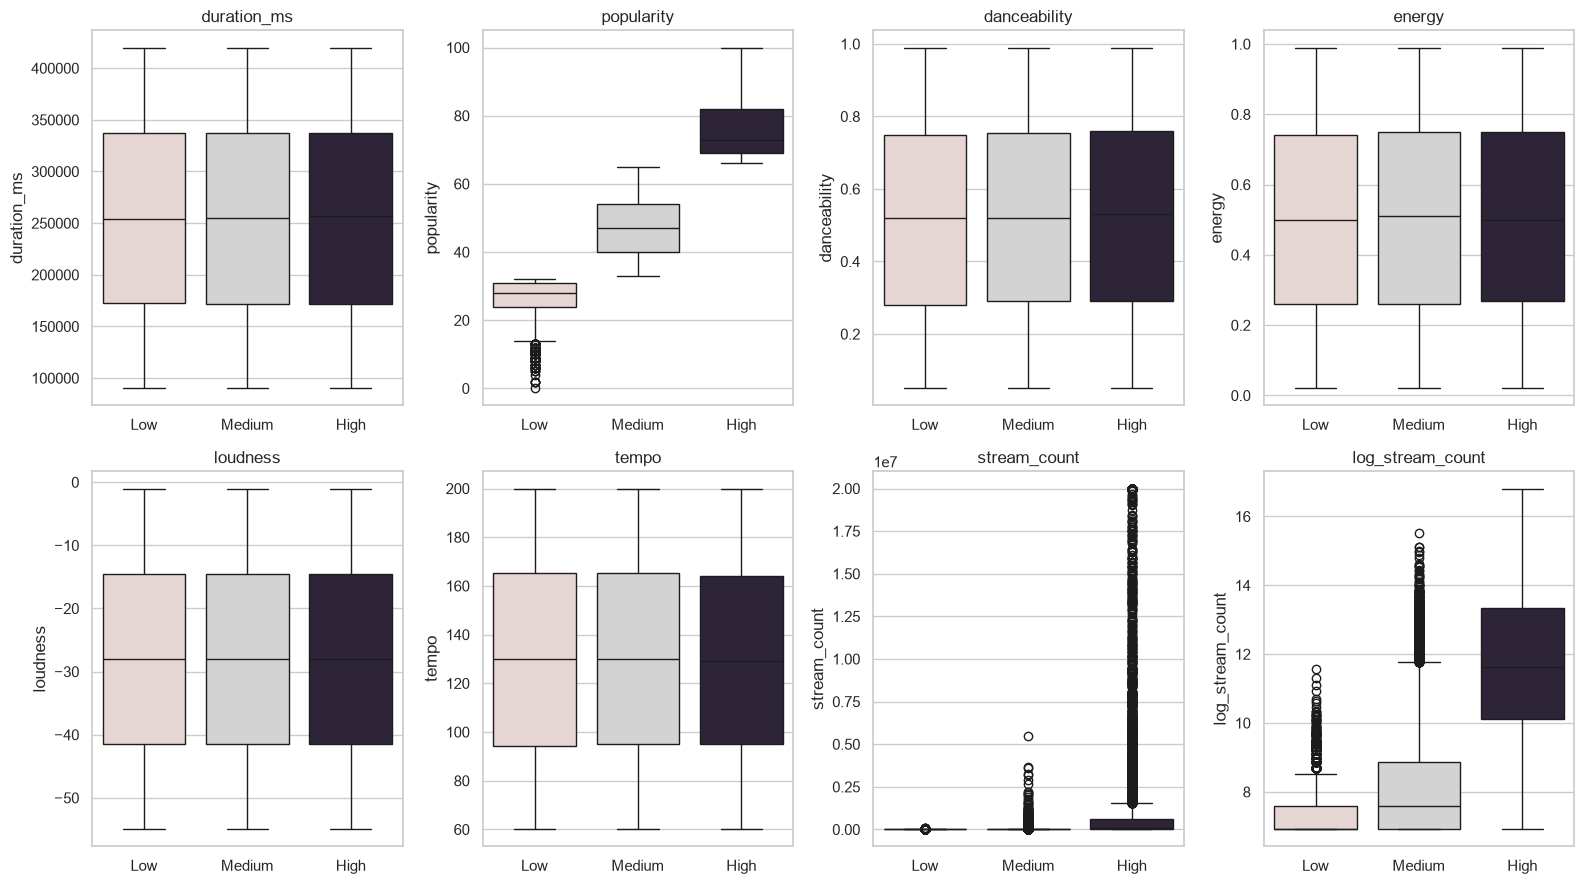

In [14]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), VARS_QUANT):
    sns.boxplot(data=df, x="popularity_category", y=col, order=classes,
                hue="popularity_category", palette=palette_classe, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Os boxplots das variáveis de áudio são semelhantes entre as faixas. A diferença mais visível está nos streams, principalmente quando usamos o log. A própria popularidade aparece separada porque ela define as categorias.

## 4. Tratamento de Dados Ausentes e Outliers

Agora vamos identificar os valores que mais se afastam dos demais. O objetivo é entender esses registros antes de decidir se algum tratamento faz sentido.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [15]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
duration_ms,-76126.12,585200.88,0.0
popularity,9.50,85.50,1806.0
danceability,-0.42,1.47,0.0
energy,-0.47,1.48,0.0
loudness,-81.92,25.95,0.0
tempo,-10.44,270.31,0.0
stream_count,-11000.00,21000.00,14160.0
log_stream_count,3.61,12.40,4152.0


### Visualizando os Outliers

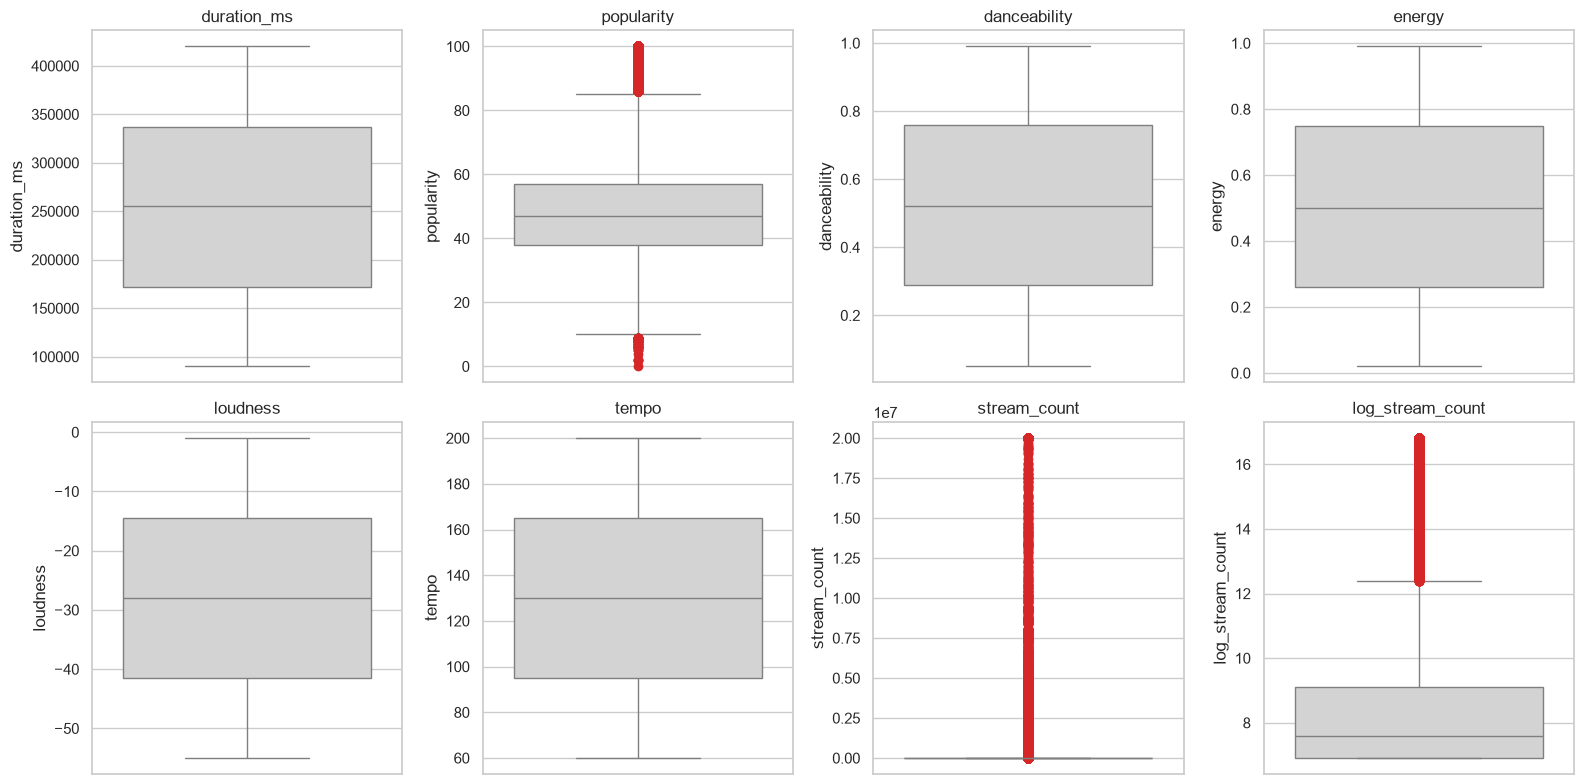

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"), ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Os pontos destacados aparecem principalmente nos gráficos de streams e de popularidade. Nos streams, vários pontos ficam muito acima da caixa, mostrando como algumas músicas se afastam das demais.

Esses pontos são marcados pela regra do IQR, mas isso não comprova erro nos dados.

### Decidindo o Tratamento dos Dados Ausentes

Não há valores ausentes no CSV. Portanto, não precisamos preencher valores nem remover linhas por esse motivo.

In [17]:
df_antes = df.copy()
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas mantidas:", len(df))

Valores ausentes: 0
Linhas mantidas: 85000


### Decidindo o Tratamento dos Outliers

Vamos manter os valores originais. Não temos informação suficiente para classificar esses registros como erros de coleta.

Para facilitar a leitura dos streams, vamos usar a coluna `log_stream_count`, que já está na base. O uso dessa coluna não remove nenhuma música.

A coluna de log corresponde a log(1 + streams)? True


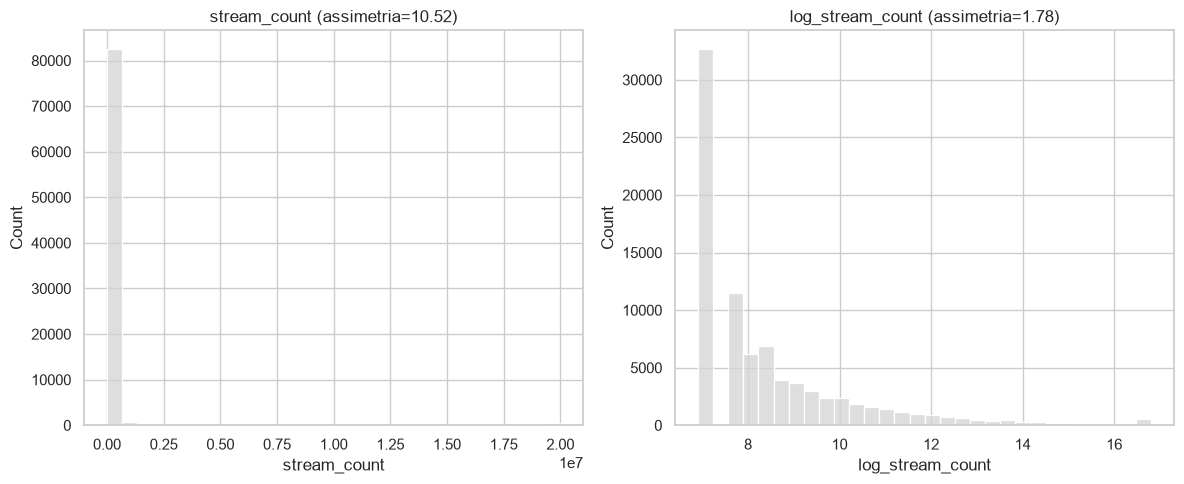

,track_name,artist_name,stream_count,popularity
142,Good anything manager think,Julie Herrera,20000000,100
1157,Of,David Rivas,20000000,100
1180,Throw,Brian Nichols,20000000,93
1317,Space,Joseph Duncan,20000000,100
1481,Upon,Monica Kim,20000000,100
1551,Team condition when if,Roberto Williamson,20000000,75
1618,Leave outside,Kelsey Nguyen,20000000,89
1633,Admit why group,Justin Saunders,20000000,91
1815,Summer such PM,Brenda Wilson,20000000,100
2097,A fact on space,Ashley Morris,20000000,91


In [18]:
print("A coluna de log corresponde a log(1 + streams)?",
      np.allclose(df["log_stream_count"], np.log1p(df["stream_count"])))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["stream_count", "log_stream_count"]):
    sns.histplot(data=df, x=col, bins=30, color=COR_NEUTRA, ax=ax)
    ax.set_title(f"{col} (assimetria={df[col].skew():.2f})")
plt.tight_layout()
plt.show()

display(df.nlargest(10, "stream_count")[["track_name", "artist_name", "stream_count", "popularity"]])

A transformação facilita bastante a leitura. No gráfico original, quase tudo fica comprimido à esquerda. No log, conseguimos enxergar melhor como os valores se distribuem.

Mesmo com a mudança de escala, a distribuição continua concentrada nos valores mais baixos e com uma cauda à direita.

## 5. Estatística Descritiva pt 2

Não removemos linhas nem alteramos os valores. Vamos conferir se as estatísticas continuam iguais.

In [19]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
duration_ms,254913.82,254920.50,95300.23,90004.00,420000.00,0.00,-1.20
popularity,48.16,47.00,14.83,0.00,100.00,0.67,0.76
danceability,0.52,0.52,0.27,0.05,0.99,-0.00,-1.19
energy,0.51,0.50,0.28,0.02,0.99,0.00,-1.20
loudness,-28.00,-27.97,15.60,-55.00,-1.00,-0.00,-1.20
tempo,129.95,129.99,40.44,60.00,200.00,0.00,-1.20
stream_count,214354.68,2000.00,1680637.47,1000.00,20000000.00,10.52,115.25
log_stream_count,8.40,7.60,1.91,6.91,16.81,1.78,3.49


### Comparando "antes"x "depois""



In [20]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
duration_ms,0.001,0.001,-1.199,-1.199,0.0,0.0
popularity,0.666,0.666,0.761,0.761,0.0,0.0
danceability,-0.001,-0.001,-1.195,-1.195,0.0,0.0
energy,0.001,0.001,-1.198,-1.198,0.0,0.0
loudness,-0.001,-0.001,-1.199,-1.199,0.0,0.0
tempo,0.000,0.000,-1.201,-1.201,0.0,0.0
stream_count,10.523,10.523,115.248,115.248,0.0,0.0
log_stream_count,1.782,1.782,3.488,3.488,0.0,0.0


As diferenças de assimetria e curtose ficaram em zero. Isso confirma que os valores das variáveis originais foram mantidos. O uso do log serviu para visualizar os streams em outra escala.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [21]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).mul(100).round(2)
    print(col)
    display(pd.concat([freq_abs.rename("quantidade"), freq_rel.rename("percentual")], axis=1))

genre


,quantidade,percentual
genre,,
Metal,7200,8.47
Jazz,7177,8.44
Hip-Hop,7160,8.42
Classical,7158,8.42
Rock,7113,8.37
Pop,7096,8.35
R&B,7084,8.33
Folk,7080,8.33
Country,7030,8.27


country


,quantidade,percentual
country,,
India,8629,10.15
Canada,8620,10.14
Japan,8582,10.10
France,8559,10.07
Germany,8551,10.06
Brazil,8490,9.99
United Kingdom,8458,9.95
Australia,8415,9.90
United States,8358,9.83


label


...

,quantidade,percentual
popularity_category,,
Medium,64111,75.42
Low,10861,12.78
High,10028,11.80


loudness_category


,quantidade,percentual
loudness_category,,
Quiet,39328,46.27
Moderate,31452,37.00
Loud,14220,16.73


is_weekend_release


,quantidade,percentual
is_weekend_release,,
False,60910,71.66
True,24090,28.34


#### Visualizando as frequências

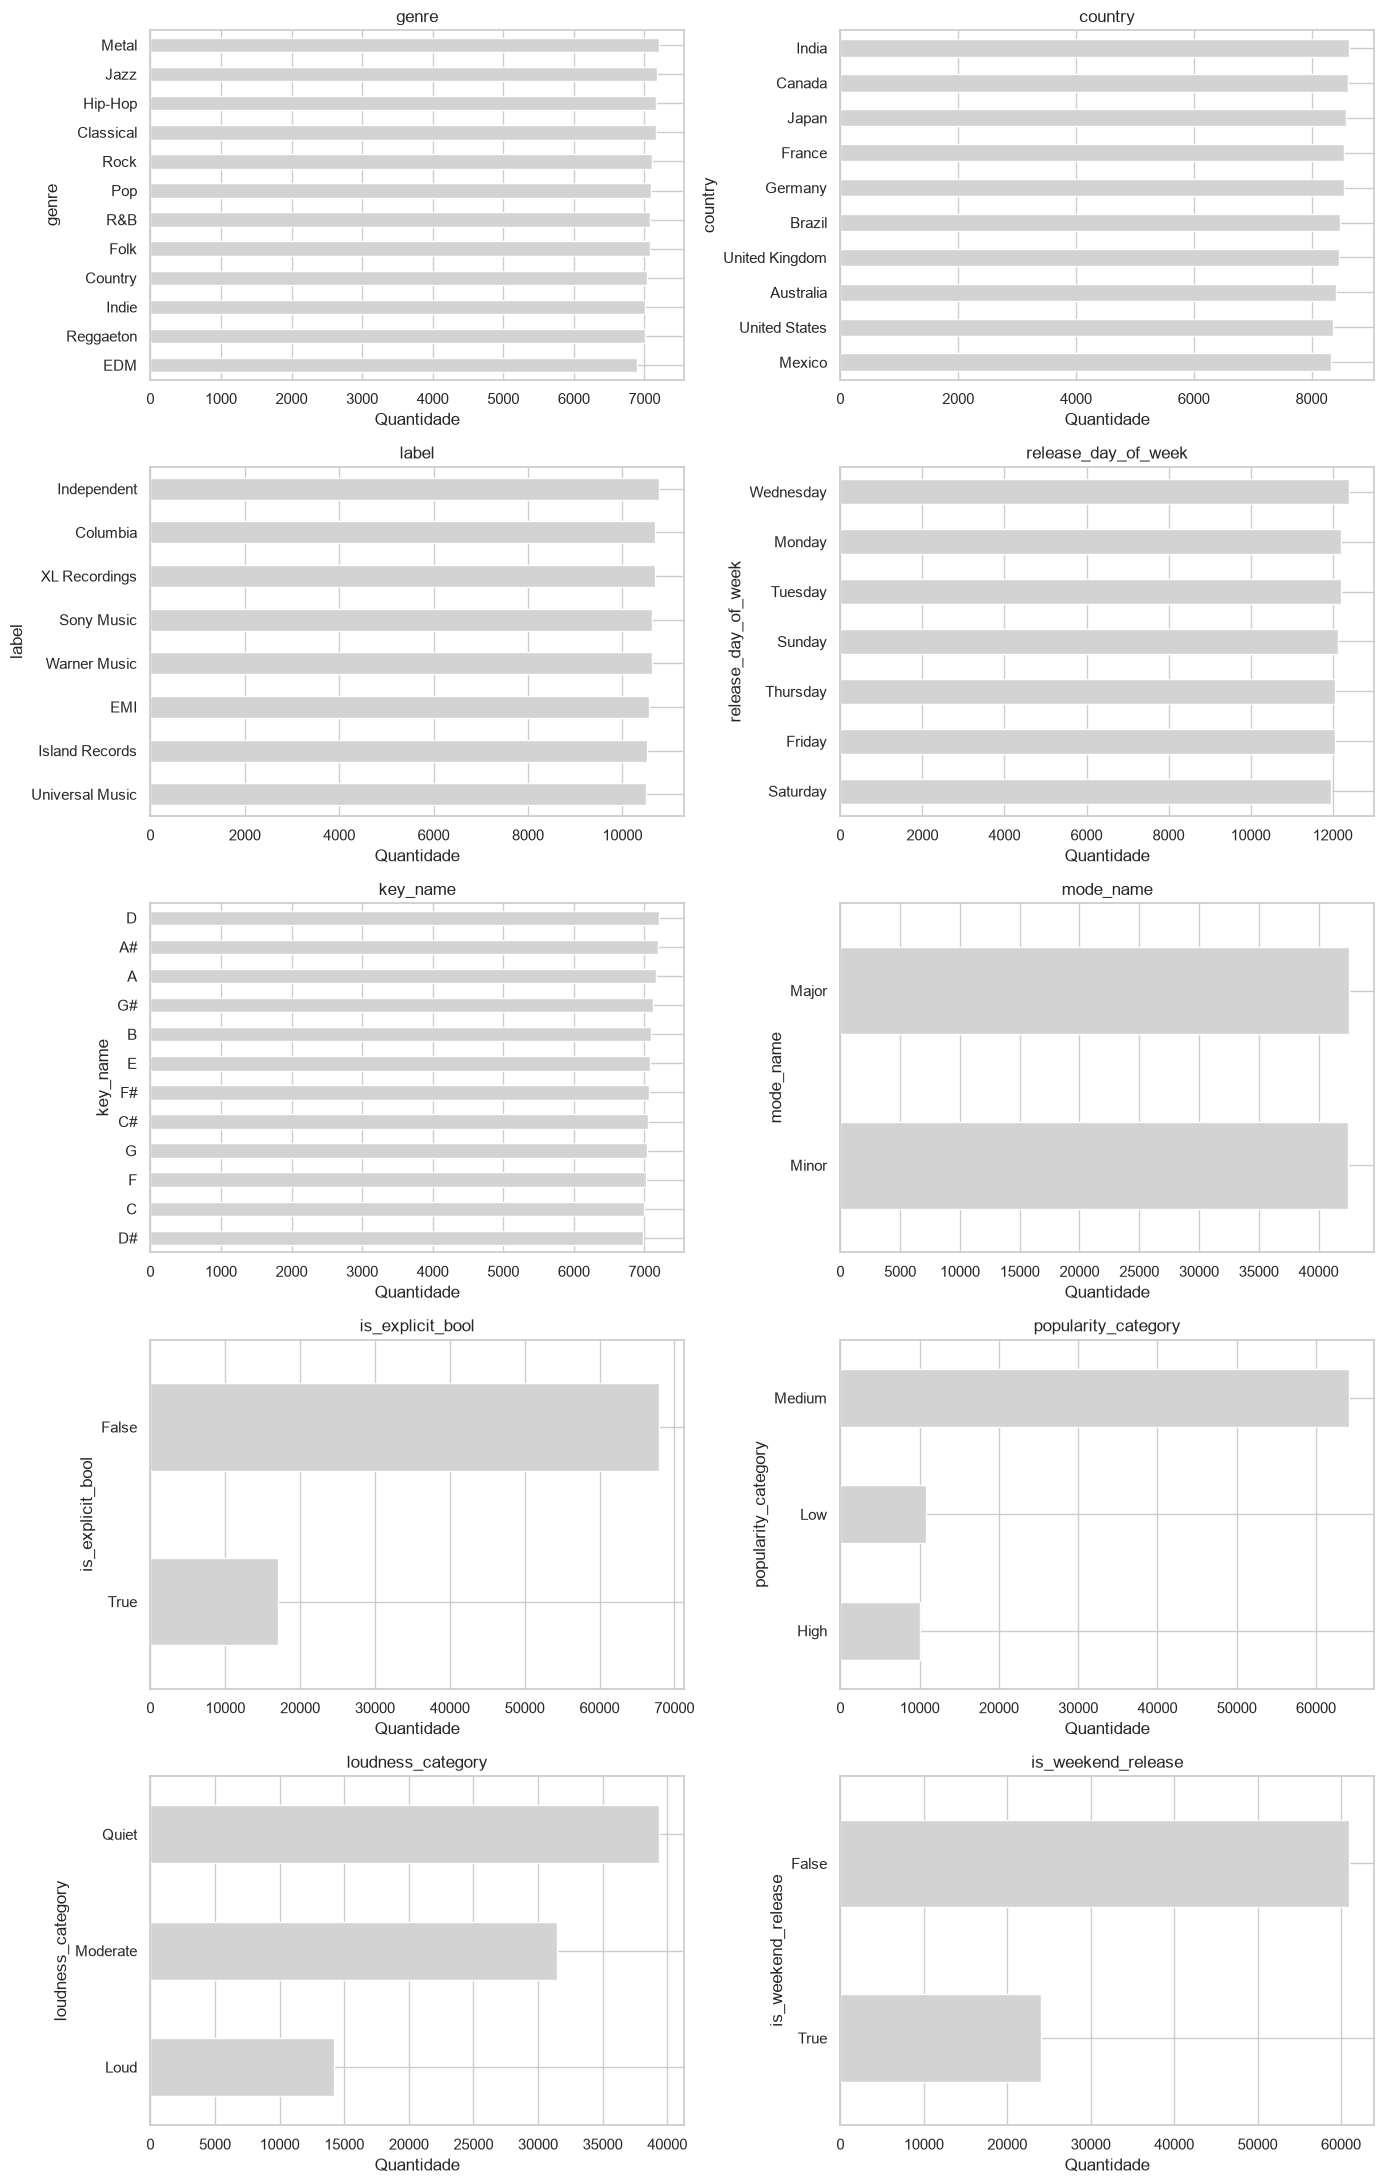

In [22]:
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for ax, col in zip(axes.ravel(), VARS_QUALI):
    df[col].value_counts().sort_values().plot(kind="barh", color=COR_NEUTRA, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Quantidade")
plt.tight_layout()
plt.show()

Gêneros, países, gravadoras e tonalidades têm barras de tamanhos próximos entre suas categorias. Major e Minor também aparecem em quantidades muito parecidas.

Já a faixa média de popularidade predomina sobre as outras. Também há mais músicas sem conteúdo explícito e mais lançamentos fora do fim de semana.

#### Desbalanceamento entre Classes

A razão de desbalanceamento divide a quantidade da maior categoria pela menor. Quanto mais próxima de 1, mais parecidas são as quantidades.

In [23]:
resumo_classes = []
for col in VARS_QUALI:
    contagens = df[col].value_counts()
    resumo_classes.append({
        "variavel": col,
        "n_classes": len(contagens),
        "maior_categoria": contagens.idxmax(),
        "percentual_maior": 100 * contagens.max() / contagens.sum(),
        "razao_desbalanceamento": contagens.max() / contagens.min()
    })
pd.DataFrame(resumo_classes).set_index("variavel").round(2)

,n_classes,maior_categoria,percentual_maior,razao_desbalanceamento
variavel,,,,
genre,12,Metal,8.47,1.04
country,10,India,10.15,1.03
label,8,Independent,12.67,1.02
release_day_of_week,7,Wednesday,14.58,1.04
key_name,12,D,8.47,1.03
mode_name,2,Major,50.01,1.00
is_explicit_bool,2,False,79.87,3.97
popularity_category,3,Medium,75.42,6.39
loudness_category,3,Quiet,46.27,2.77


A faixa média de popularidade tem bem mais músicas que as faixas baixa e alta. Por isso, comparar apenas as contagens pode enganar. Nas próximas comparações, vamos observar o formato das distribuições e os percentuais dentro dos grupos.

### Análise Bivariada

Agora vamos observar como as variáveis se relacionam com a popularidade e os streams.

#### Quantitativa x Quantitativa - Correlação

Pearson mede a relação linear. Spearman compara a ordem dos valores e ajuda a observar relações crescentes ou decrescentes, mesmo que não formem uma linha reta.

Vamos comparar os dois. Correlação não mostra que uma variável causa a outra.

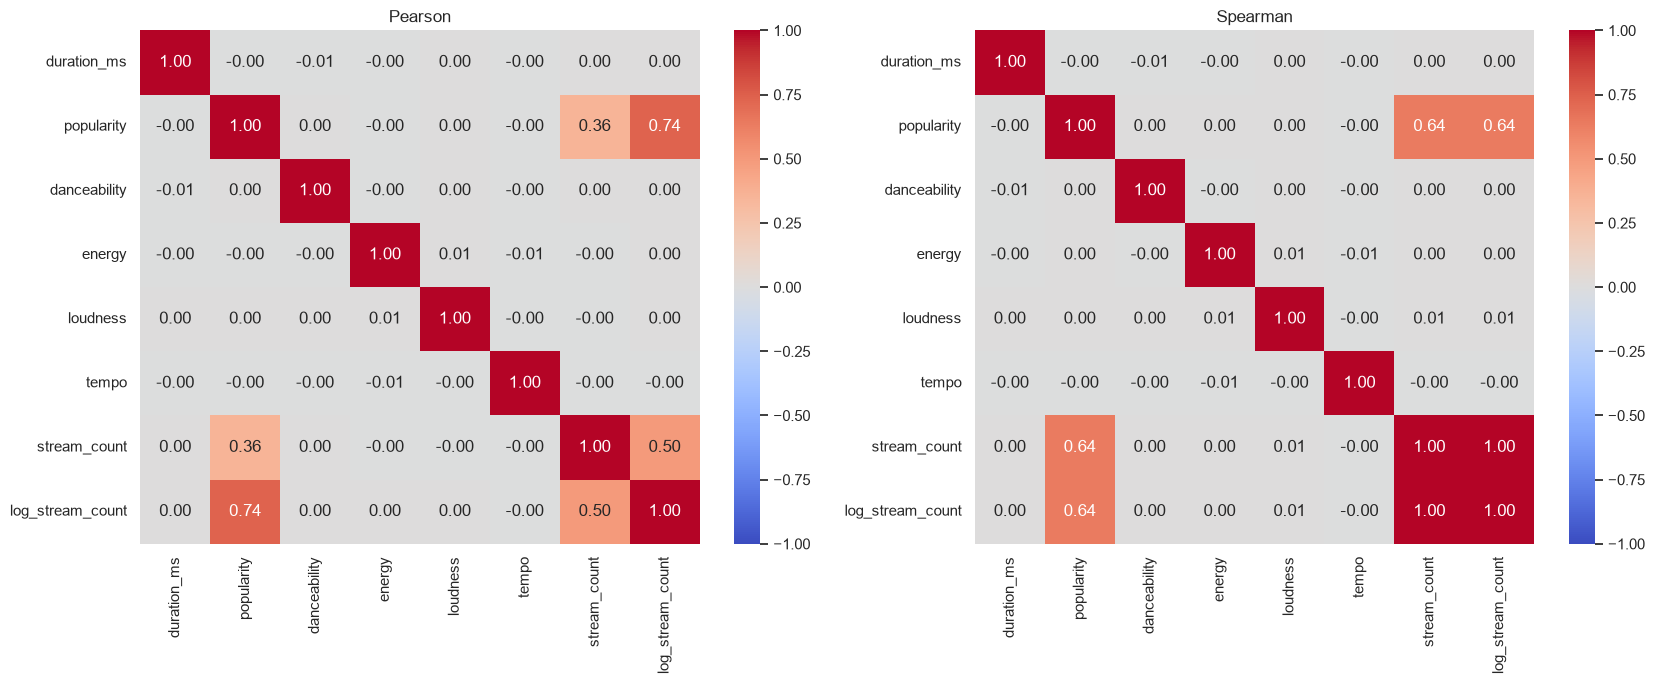

In [24]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, matriz, titulo in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

Na matriz de correlação, a relação entre streams e popularidade se destaca. Em Pearson, ela aparece mais forte quando usamos o log de streams.

As relações de duração, dançabilidade, energia, volume e andamento com a popularidade ficam próximas da região neutra da escala de cores, sem um destaque claro.

Streams e log de streams aparecem fortemente relacionados entre si, pois representam a mesma informação em escalas diferentes.

Vamos destacar as correlações com a popularidade.

In [25]:
pd.DataFrame({
    "Pearson": corr_pearson["popularity"],
    "Spearman": corr_spearman["popularity"]
}).drop(index="popularity").round(3)

,Pearson,Spearman
duration_ms,-0.001,-0.001
danceability,0.003,0.001
energy,-0.000,0.000
loudness,0.003,0.005
tempo,-0.003,-0.002
stream_count,0.358,0.639
log_stream_count,0.739,0.639


#### Dispersão entre duas variáveis quantitativas

Músicas com mais streams também têm maior popularidade? Vamos usar o log de streams para enxergar melhor a relação.

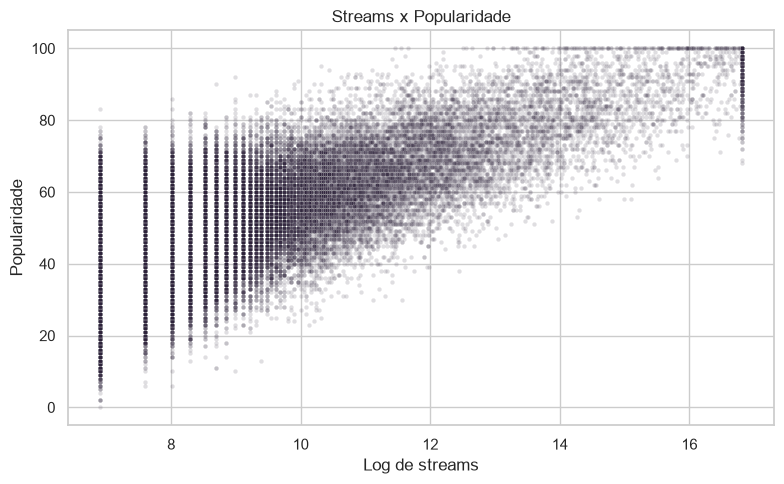

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="log_stream_count", y="popularity", color=COR_DESTAQUE, alpha=0.15, s=10)
plt.title("Streams x Popularidade")
plt.xlabel("Log de streams")
plt.ylabel("Popularidade")
plt.tight_layout()
plt.show()

Existe uma tendência crescente: valores maiores de streams aparecem junto de popularidades maiores. Porém, os pontos estão espalhados, então a relação não é exata.

Também há muitas músicas com o mesmo valor baixo de streams e popularidades diferentes. Só a contagem de streams não determina toda a variação da popularidade.

#### Quantitativa x Qualitativa: Comparando Grupos

Vamos comparar os streams entre as três faixas de popularidade. A mediana ajuda porque a média é bastante afetada pelas contagens extremas.

,count,mean,median
popularity_category,,,
Low,10861,1717.43,1000.0
Medium,64111,12571.13,2000.0
High,10028,1734697.55,113000.0


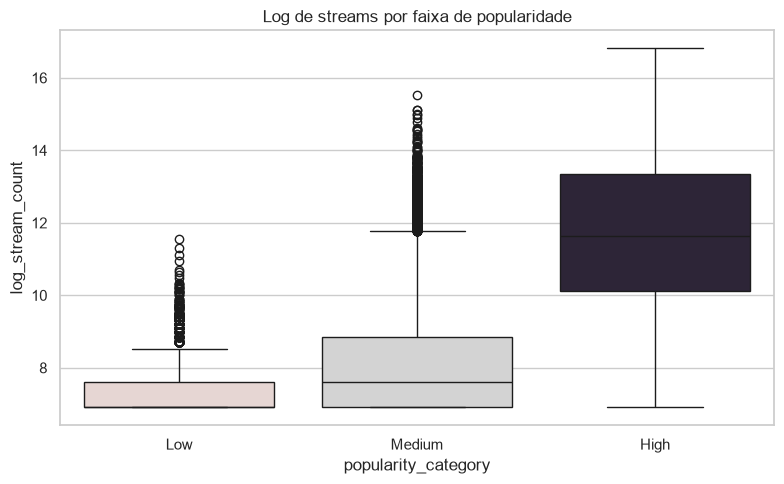

In [27]:
resumo_popularidade = df.groupby("popularity_category")["stream_count"].agg(["count", "mean", "median"])
display(resumo_popularidade.reindex(classes).round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="popularity_category", y="log_stream_count", order=classes,
            hue="popularity_category", palette=palette_classe, legend=False)
plt.title("Log de streams por faixa de popularidade")
plt.tight_layout()
plt.show()

No boxplot, a faixa alta aparece em valores maiores de log de streams e também tem uma dispersão maior.

As distribuições ainda se sobrepõem. Portanto, a faixa alta tende a ter mais streams, mas isso não vale como regra para toda música.

### Popularidade por gênero

Vamos comparar a popularidade entre os gêneros. O Kruskal-Wallis ajuda a verificar diferenças entre as distribuições, sem exigir normalidade.

,count,mean,median
genre,,,
Country,7030,48.17,46.0
Jazz,7177,47.85,46.0
Reggaeton,7001,47.88,46.0
Rock,7113,47.97,46.0
Folk,7080,48.10,47.0
Hip-Hop,7160,48.36,47.0
EDM,6894,48.20,47.0
Classical,7158,48.36,47.0
Metal,7200,48.19,47.0


Kruskal-Wallis: estatística=10.919, p-valor=0.4501


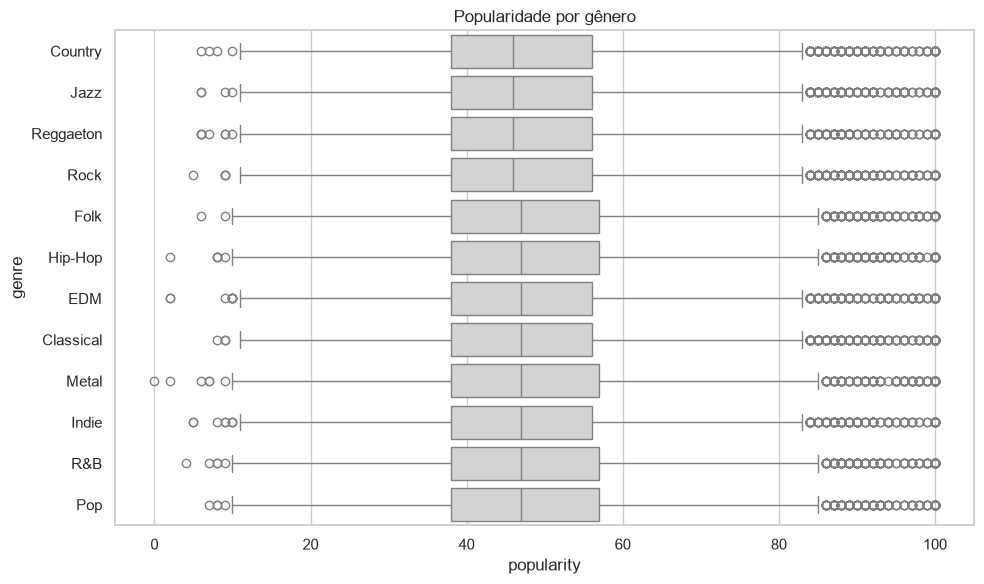

In [28]:
resumo_genero = df.groupby("genre")["popularity"].agg(["count", "mean", "median"]).sort_values("median")
display(resumo_genero.round(2))

grupos = [grupo["popularity"].values for _, grupo in df.groupby("genre")]
stat_kw, p_kw = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: estatística={stat_kw:.3f}, p-valor={p_kw:.4g}")

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="popularity", y="genre", order=resumo_genero.index, color=COR_NEUTRA)
plt.title("Popularidade por gênero")
plt.tight_layout()
plt.show()

Os boxplots de popularidade por gênero são muito parecidos: as linhas centrais e as caixas ficam em posições próximas.

Visualmente, não aparece uma separação clara entre os gêneros. O resultado do Kruskal-Wallis não está nas saídas salvas, então essa observação se limita ao gráfico.

#### Qualitativa x Qualitativa

Vamos comparar as faixas de popularidade dentro de cada gênero. Usamos percentuais por linha, pois os gêneros têm quantidades diferentes de músicas.

Qui-quadrado: estatística=23.920, p-valor=0.3514


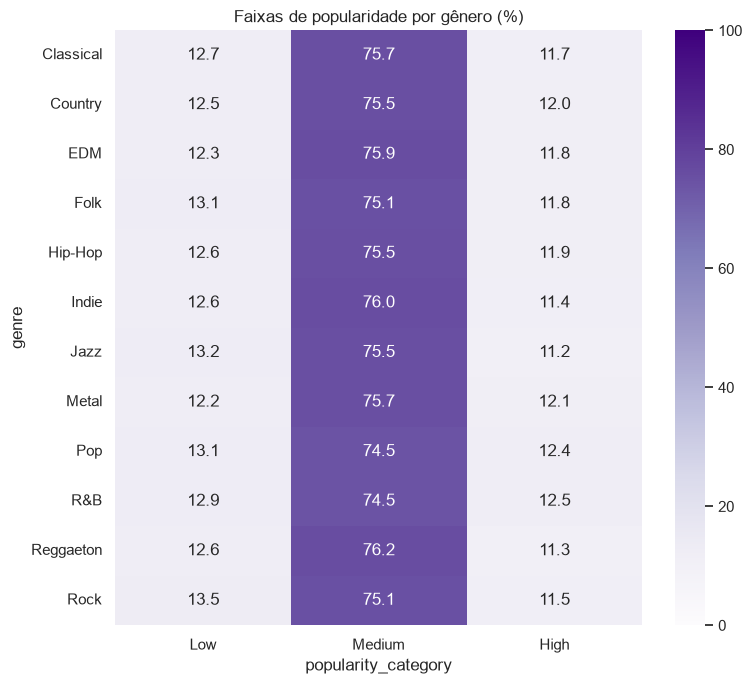

In [29]:
contingencia = pd.crosstab(df["genre"], df["popularity_category"]).reindex(columns=classes)
percentuais = contingencia.div(contingencia.sum(axis=1), axis=0) * 100
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)
print(f"Qui-quadrado: estatística={chi2:.3f}, p-valor={p_chi2:.4g}")

plt.figure(figsize=(8, 7))
sns.heatmap(percentuais, annot=True, fmt=".1f", cmap="Purples", vmin=0, vmax=100)
plt.title("Faixas de popularidade por gênero (%)")
plt.tight_layout()
plt.show()

A faixa média predomina em todos os gêneros. Os percentuais mostrados no mapa de calor são próximos entre os gêneros, inclusive na faixa alta.

O resultado do qui-quadrado não está nas saídas salvas. Portanto, o gráfico permite comparar os percentuais, mas não afirmar a conclusão do teste.

#### Comparando países e gravadoras

A base não traz sexo ou idade dos artistas, então a análise de fairness do exemplo anterior não se aplica diretamente. Aqui vamos comparar os países e as gravadoras registrados no arquivo. Isso descreve os grupos, sem concluir que existe justiça ou injustiça no Spotify.

In [30]:
for col in ["country", "label"]:
    print(col)
    display(df.groupby(col)["popularity"].agg(["count", "mean", "median"]).round(2))

country


,count,mean,median
country,,,
Australia,8415,48.05,47.0
Brazil,8490,48.31,47.0
Canada,8620,48.06,46.0
France,8559,48.33,47.0
Germany,8551,48.07,46.0
India,8629,48.01,47.0
Japan,8582,48.35,47.0
Mexico,8338,47.96,46.0
United Kingdom,8458,48.41,47.0


label


,count,mean,median
label,,,
Columbia,10690,48.09,46.0
EMI,10574,48.30,47.0
Independent,10767,48.26,47.0
Island Records,10527,48.00,46.0
Sony Music,10631,48.33,47.0
Universal Music,10505,48.20,47.0
Warner Music,10619,47.90,46.0
XL Recordings,10687,48.21,47.0


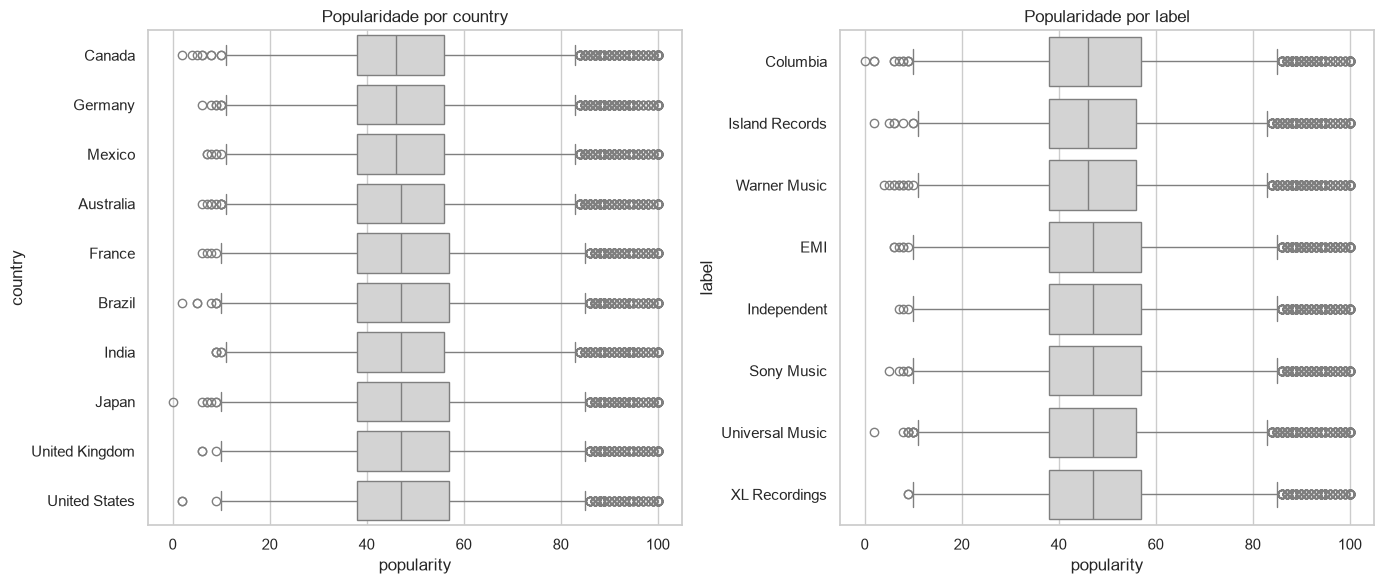

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col in zip(axes, ["country", "label"]):
    ordem = df.groupby(col)["popularity"].median().sort_values().index
    sns.boxplot(data=df, x="popularity", y=col, order=ordem, color=COR_NEUTRA, ax=ax)
    ax.set_title(f"Popularidade por {col}")
plt.tight_layout()
plt.show()

Os boxplots por país e por gravadora são muito parecidos. As caixas e as linhas centrais ficam em posições próximas, e a dispersão também é semelhante.

Visualmente, não aparece um grupo claramente separado dos demais em popularidade.

#### Outliers bivariados

Vamos destacar na dispersão as músicas acima do limite superior do IQR em streams. Assim podemos observar como esses registros se comportam junto da popularidade.

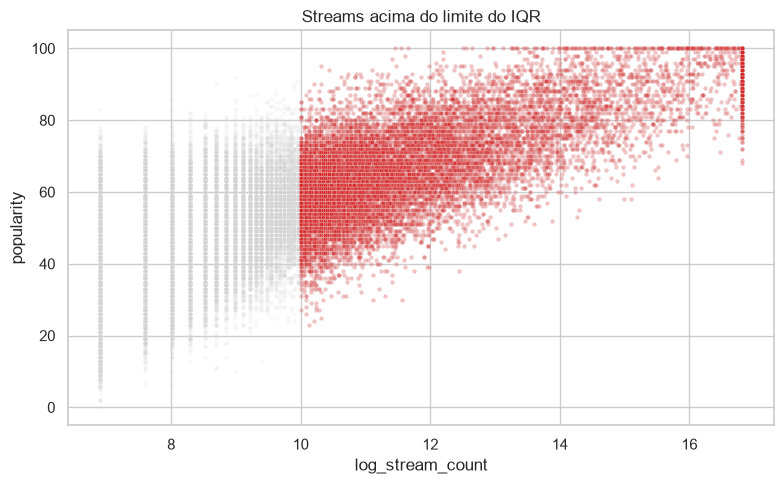

In [32]:
_, limite_superior = limites_iqr(df["stream_count"])
outliers_streams = df[df["stream_count"] > limite_superior]

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="log_stream_count", y="popularity", color=COR_NEUTRA, alpha=0.15, s=10)
sns.scatterplot(data=outliers_streams, x="log_stream_count", y="popularity", color=COR_ALERTA, alpha=0.25, s=10)
plt.title("Streams acima do limite do IQR")
plt.tight_layout()
plt.show()

Os registros destacados ficam à direita, como esperado pelo corte nos streams, mas variam bastante em popularidade. Eles acompanham a tendência crescente geral.

O gráfico ajuda a observar a combinação das variáveis. Ele não é suficiente para classificar um ponto como erro ou comprovar uma anomalia conjunta. Vamos manter esses registros.

#### Análise Multivariada

##### Energia, dançabilidade e popularidade

Vamos olhar energia e dançabilidade juntas, separando as músicas pelas faixas de popularidade.

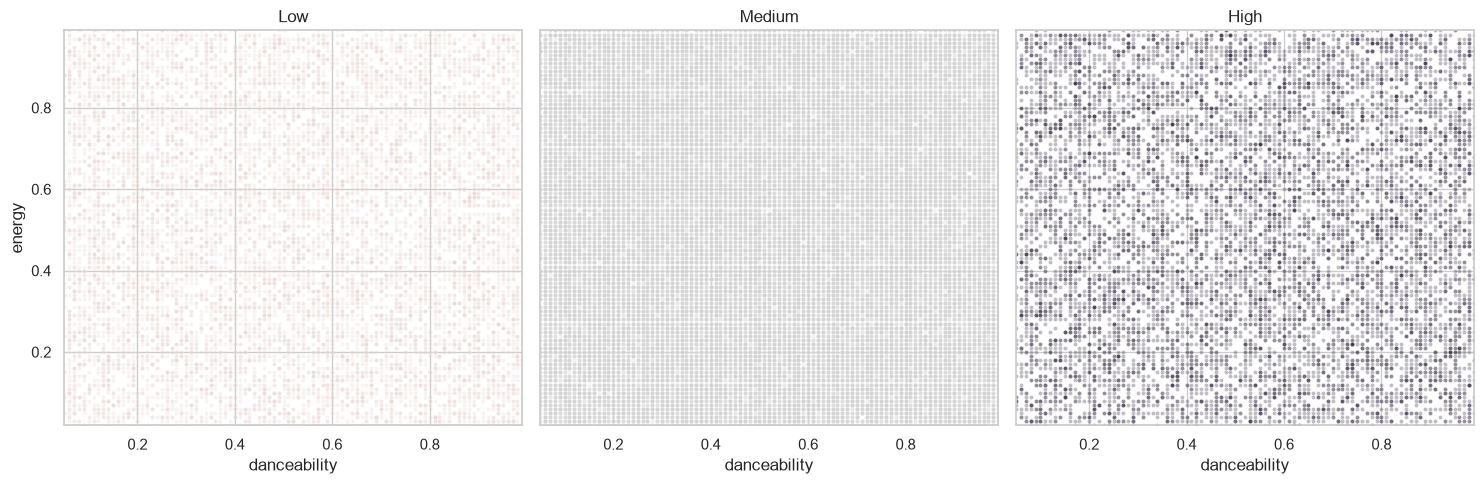

,danceability,energy
popularity_category,,
Low,0.52,0.50
Medium,0.52,0.51
High,0.53,0.50


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, classe in zip(axes, classes):
    grupo = df[df["popularity_category"] == classe]
    sns.scatterplot(data=grupo, x="danceability", y="energy", color=palette_classe[classe], alpha=0.3, s=8, ax=ax)
    ax.set_xlim(df["danceability"].min(), df["danceability"].max())
    ax.set_ylim(df["energy"].min(), df["energy"].max())
    ax.set_title(classe)
plt.tight_layout()
plt.show()

display(df.groupby("popularity_category")[["danceability", "energy"]].median().reindex(classes).round(3))

As três faixas ocupam praticamente a mesma região de energia e dançabilidade.

Não aparece uma combinação claramente diferente para as músicas de popularidade alta. A densidade maior de pontos na faixa média também reflete que ela tem mais músicas.

## Principais conclusões

- As verificações da base não apontaram valores ausentes ou linhas duplicadas. Mantivemos os dados originais.
- Os streams se concentram nos valores baixos, com poucas músicas chegando a contagens muito maiores. O log facilita a leitura, mas a distribuição continua assimétrica.
- Na dispersão, streams e popularidade apresentam uma tendência crescente. O boxplot mostra valores maiores de log de streams na faixa alta, embora exista sobreposição entre os grupos.
- Duração, dançabilidade, energia, volume e andamento têm correlações próximas de zero com a popularidade. Energia e dançabilidade juntas também não mostram separação clara entre as faixas.
- A faixa média reúne a maior parte das músicas. Os gráficos de popularidade por gênero, país e gravadora mostram distribuições visualmente parecidas.
- O dataset traz fortes indícios de ser sintético, muitos valores apresentam distribuições suspeitas e isso acabou afetando um pouco a fluidez da análise.

## Declaração de Uso de IA

O Codex (ChatGPT) foi usado para adaptar os trechos para corrigir o código e ajudar a interpretar os gráficos a partir do CSV. Foram mantidas as categorias e os valores da base. Os exemplos que não se aplicavam foram substituídos por comparações de músicas, gêneros, países e gravadoras. Não foram criados registros nem preenchidos dados.

---
## Exportação do dataset tratado

Nesta EDA não removemos linhas nem alteramos valores. Por isso, o "tratamento" aqui é só escolher as colunas que o app vai usar, o que deixa o arquivo menor (de 19 MB para 12) e o app mais rápido.

- `data/raw/spotify_data_processed.csv`: dataset original, como veio do Kaggle (fica fora do Git).
- `data/clean/dataset.csv`: dataset **tratado**, que o `app.py` lê (vai para o Git, porque o Streamlit Cloud só enxerga o que está no GitHub).

Rode o notebook **do início ao fim** antes desta seção.

In [34]:
COLUNAS_APP = [
    # identificação da música
    "track_name", "artist_name",
    # categorias
    "genre", "country", "label", "release_year", "popularity_category", "is_explicit_bool",
    # quantitativas
    "popularity", "stream_count", "log_stream_count", "duration_minutes",
    "danceability", "energy", "loudness", "tempo",
]

df_clean = df[COLUNAS_APP]
df_clean.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df_clean.shape[0]} linhas x {df_clean.shape[1]} colunas")

Clean salvo em ..\data\clean\dataset.csv — 85000 linhas x 16 colunas
